
# Web Traffic Analytics

**Workora Virtual Internship — Data Analytics**

## Objective
Analyze website traffic channels, bounce rates, session durations,
conversion performance, and page-level engagement to identify
opportunities for website improvement.

## Tools
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook

## Project Workflow
1. Load and inspect the dataset
2. Clean and validate the data
3. Calculate web traffic KPIs
4. Compare traffic channel performance
5. Analyze page-level performance and funnel limitations
6. Create visualizations
7. Generate a PDF dashboard and summarize findings

# Web Traffic Analytics

**Workora Virtual Internship — Data Analytics**

## Objective
Analyze website traffic channels, bounce rates, session durations,
conversion performance, and page-level engagement to identify
opportunities for website improvement.

## Tools
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook

## Project Workflow
1. Load and inspect the dataset
2. Clean and validate the data
3. Calculate web traffic KPIs
4. Compare traffic channel performance
5. Analyze page-level performance and funnel limitations
6. Create visualizations
7. Generate a PDF dashboard and summarize findings


### Import Libraries

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display
print("Libraries Imported Successfully")

Libraries Imported Successfully


### Project Paths

In [5]:
DATA_PATH = Path("../data/web_traffic_sample.csv")
OUTPUT_DIR = Path("outputs")
CHART_DIR = OUTPUT_DIR / "charts"

OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(exist_ok=True)
print("Dataset Path", DATA_PATH.resolve())
print("Output Folder", OUTPUT_DIR.resolve())

Dataset Path C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Web Traffic Analytics\data\web_traffic_sample.csv
Output Folder C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Web Traffic Analytics\notebooks\outputs


### Load the Dataset

In [6]:
df = pd.read_csv(DATA_PATH)

print("Dataset Loaded Successfully!")
print("Rows", df.shape[0])
print("Columns", df.shape[1])

print(df.head())

Dataset Loaded Successfully!
Rows 10
Columns 9
   SessionID        Date      PagePath         Source DeviceCategory  \
0  SESS-5001  2026-06-10      /landing  Google Search         Mobile   
1  SESS-5002  2026-06-10      /courses         Direct        Desktop   
2  SESS-5003  2026-06-10  /blog/python       LinkedIn         Mobile   
3  SESS-5004  2026-06-11     /register     Google Ads        Desktop   
4  SESS-5005  2026-06-11      /pricing         Direct        Desktop   

   SessionDurationSec  PageViews Converted  BounceRate  
0                 145          3       Yes         0.0  
1                 420          8       Yes         0.0  
2                  45          1        No         1.0  
3                 210          4       Yes         0.0  
4                  60          2        No         0.0  


### Initial Data Inspection

In [7]:
# Check the shape of the dataset
print("Dataset Shape :", df.shape)

# Check the Columns
print("\nColumns Names :")
print(df.columns.to_list())

# Check the Data Types and null counts
print("\nData Types and Non-null Counts :")
print(df.info())

# Check missing values
print("\nMissing Values :")
print(df.isnull().sum().to_frame("Missing Values"))

# CHeck duplicate values of session ID
print("\nDuplicate Session IDs :", df["SessionID"].duplicated().sum())

# Check the summary of the entire dataset
print("\nStatical Summary :")
print(df.describe(include="all").T)

Dataset Shape : (10, 9)

Columns Names :
['SessionID', 'Date', 'PagePath', 'Source', 'DeviceCategory', 'SessionDurationSec', 'PageViews', 'Converted', 'BounceRate']

Data Types and Non-null Counts :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SessionID           10 non-null     object 
 1   Date                10 non-null     object 
 2   PagePath            10 non-null     object 
 3   Source              10 non-null     object 
 4   DeviceCategory      10 non-null     object 
 5   SessionDurationSec  10 non-null     int64  
 6   PageViews           10 non-null     int64  
 7   Converted           10 non-null     object 
 8   BounceRate          10 non-null     float64
dtypes: float64(1), int64(2), object(6)
memory usage: 848.0+ bytes
None

Missing Values :
                    Missing Values
SessionID                        0
D

### Data Cleaning and Validation

In this step, I will clean and validate the web traffic dataset to ensure that the data is accurate, consistent, and ready for analysis.

The following tasks will be performed:

* **Correct Data Types:** Convert columns to their appropriate data types, such as dates, integers, and floating-point numbers.
* **Standardize Text:** Remove unnecessary spaces and make text values consistent across relevant columns.
* **Check Duplicate Sessions:** Identify and handle duplicate session records to avoid counting the same session multiple times.
* **Handle Missing Values:** Check for missing values and decide how to handle them based on the column and its importance.
* **Validate Numerical Fields:** Check numerical columns for invalid values, unexpected negative numbers, and values outside the expected range.
* **Verify Data Quality:** Review the dataset after cleaning to confirm that it is consistent and suitable for exploratory data analysis (EDA).

**Expected Outcome:** A clean, consistent, and validated dataset that can be used to analyze website traffic, user engagement, session duration, and other performance metrics.


In [13]:

# Keep the original data safe for reference
df_raw = df.copy()

# Remove leading/trailing whitespace from text fields
text_columns = [
    "SessionID", "PagePath", "Source",
    "DeviceCategory", "Converted"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Convert Data Types
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["SessionDurationSec"] = pd.to_numeric(df["SessionDurationSec"], errors="coerce")

df["PageViews"] = pd.to_numeric(df["PageViews"], errors="coerce")
df["BounceRate"] = pd.to_numeric(df["BounceRate"], errors="coerce")

df["Converted"] = df["Converted"].str.title()

df = df.drop_duplicates(subset="SessionID", keep="first").copy()


# Validate Values
Validation = {
    "Missing Values ":int(df.isnull().sum().sum()),
    "Duplicate Session IDs": int(df["SessionID"].duplicated().sum()),
    "Invalid Dates":int(df["Date"].isna().sum()),
    "Invalid Conversion Lables": int((~df["Converted"].isin(["Yes","No"])).sum()),
    "Invalid Page Views": int((df["PageViews"] < 1).sum()),
    "Negative Session Durations": int((df["SessionDurationSec"] < 0).sum()),
    "Invalid Bounce Values": int((~df["BounceRate"].isin([0 ,1])).sum())
}

display(pd.DataFrame(
    list(Validation.items()),
    columns=["Validation Check", "Count"]

))

display(df.head())

,Validation Check,Count
0,Missing Values,0
1,Duplicate Session IDs,0
2,Invalid Dates,0
3,Invalid Conversion Lables,0
4,Invalid Page Views,0
5,Negative Session Durations,0
6,Invalid Bounce Values,0


,SessionID,Date,PagePath,Source,DeviceCategory,SessionDurationSec,PageViews,Converted,BounceRate
0,SESS-5001,2026-06-10,/landing,Google Search,Mobile,145,3,Yes,0.0
1,SESS-5002,2026-06-10,/courses,Direct,Desktop,420,8,Yes,0.0
2,SESS-5003,2026-06-10,/blog/python,LinkedIn,Mobile,45,1,No,1.0
3,SESS-5004,2026-06-11,/register,Google Ads,Desktop,210,4,Yes,0.0
4,SESS-5005,2026-06-11,/pricing,Direct,Desktop,60,2,No,0.0


### Prepare analysis columns

In [14]:

source_mapping = {
    "Google Search": "Organic",
    "Google Ads": "Ads",
    "LinkedIn": "Social",
    "Direct": "Direct"
}

df["TrafficChannel"] = df["Source"].map(source_mapping).fillna("Other")

df["ConversionFlag"] = df["Converted"].map({
    "Yes": 1,
    "No": 0
})

# The sample's BounceRate is binary: 0 or 1.
# Treat it as a session-level bounce flag for this analysis.
df["Bounced"] = df["BounceRate"]

print("Traffic channels:")
print(df["TrafficChannel"].value_counts())

display(df[[
    "SessionID", "Source", "TrafficChannel",
    "SessionDurationSec", "PageViews",
    "Converted", "Bounced"
]].head())


Traffic channels:
TrafficChannel
Direct     3
Organic    2
Ads        2
Other      2
Social     1
Name: count, dtype: int64


,SessionID,Source,TrafficChannel,SessionDurationSec,PageViews,Converted,Bounced
0,SESS-5001,Google Search,Organic,145,3,Yes,0.0
1,SESS-5002,Direct,Direct,420,8,Yes,0.0
2,SESS-5003,LinkedIn,Social,45,1,No,1.0
3,SESS-5004,Google Ads,Ads,210,4,Yes,0.0
4,SESS-5005,Direct,Direct,60,2,No,0.0


### Calculate overall KPIs

In [15]:

total_sessions = df["SessionID"].nunique()
total_conversions = int(df["ConversionFlag"].sum())

overall_kpis = pd.DataFrame({
    "Metric": [
        "Total Sessions",
        "Total Conversions",
        "Conversion Rate (%)",
        "Bounce Rate (%)",
        "Average Session Duration (seconds)",
        "Average Session Duration (minutes)",
        "Average Pageviews per Session"
    ],
    "Value": [
        total_sessions,
        total_conversions,
        df["ConversionFlag"].mean() * 100,
        df["Bounced"].mean() * 100,
        df["SessionDurationSec"].mean(),
        df["SessionDurationSec"].mean() / 60,
        df["PageViews"].mean()
    ]
})

display(overall_kpis.round(2))


,Metric,Value
0,Total Sessions,10.00
1,Total Conversions,5.00
2,Conversion Rate (%),50.00
3,Bounce Rate (%),30.00
4,Average Session Duration (seconds),170.50
5,Average Session Duration (minutes),2.84
6,Average Pageviews per Session,3.40


### Compare traffic channels

In [16]:

channel_summary = df.groupby("TrafficChannel").agg(
    Sessions=("SessionID", "nunique"),
    Conversions=("ConversionFlag", "sum"),
    BounceRate=("Bounced", "mean"),
    AvgSessionDurationSec=("SessionDurationSec", "mean"),
    AvgPageviewsPerSession=("PageViews", "mean")
).reset_index()

channel_summary["ConversionRate"] = (
    channel_summary["Conversions"] / channel_summary["Sessions"] * 100
)

channel_summary["BounceRate"] *= 100

channel_summary = channel_summary.round(2)

display(channel_summary)

channel_summary.to_csv(
    OUTPUT_DIR / "traffic_channel_summary.csv",
    index=False
)


,TrafficChannel,Sessions,Conversions,BounceRate,AvgSessionDurationSec,AvgPageviewsPerSession,ConversionRate
0,Ads,2,2,0.0,250.0,4.50,100.00
1,Direct,3,1,0.0,220.0,4.33,33.33
2,Organic,2,2,0.0,227.5,4.50,100.00
3,Other,2,0,100.0,22.5,1.00,0.00
4,Social,1,0,100.0,45.0,1.00,0.00


### Page-level performance

In [17]:

page_summary = df.groupby("PagePath").agg(
    Sessions=("SessionID", "nunique"),
    Conversions=("ConversionFlag", "sum"),
    BounceRate=("Bounced", "mean"),
    AvgDurationSec=("SessionDurationSec", "mean"),
    AvgPageviews=("PageViews", "mean")
).reset_index()

page_summary["BounceRate"] *= 100

display(page_summary.round(2))

page_summary.to_csv(
    OUTPUT_DIR / "page_performance_summary.csv",
    index=False
)


,PagePath,Sessions,Conversions,BounceRate,AvgDurationSec,AvgPageviews
0,/blog/ai-trends,1,0,100.00,30.0,1.0
1,/blog/python,1,0,100.00,45.0,1.0
2,/contact,1,0,0.00,180.0,3.0
3,/courses,1,1,0.00,420.0,8.0
4,/courses/data-science,1,1,0.00,310.0,6.0
5,/landing,3,2,33.33,150.0,3.0
6,/pricing,1,0,0.00,60.0,2.0
7,/register,1,1,0.00,210.0,4.0


### Visualize traffic channels

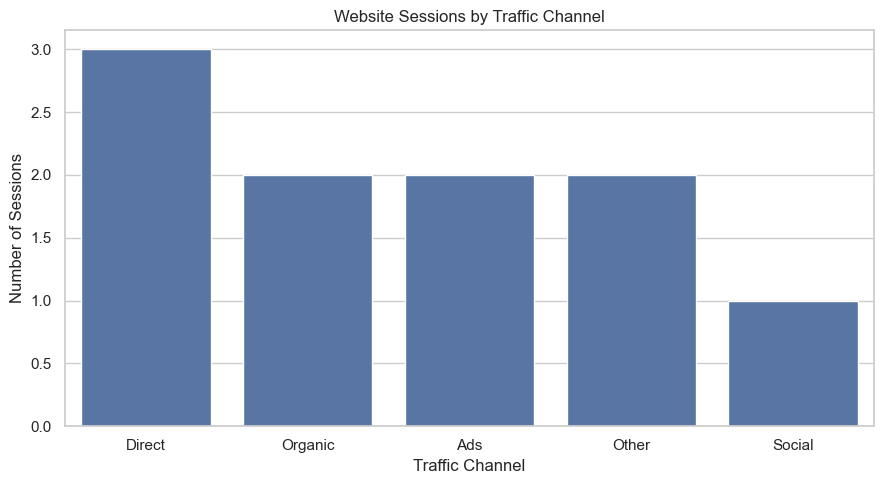

In [18]:
# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


fig, ax = plt.subplots(figsize=(9, 5))

sns.countplot(
    data=df,
    x="TrafficChannel",
    order=df["TrafficChannel"].value_counts().index,
    ax=ax
)

ax.set_title("Website Sessions by Traffic Channel")
ax.set_xlabel("Traffic Channel")
ax.set_ylabel("Number of Sessions")

plt.tight_layout()
fig.savefig(CHART_DIR / "traffic_by_channel.png", dpi=200)
plt.show()


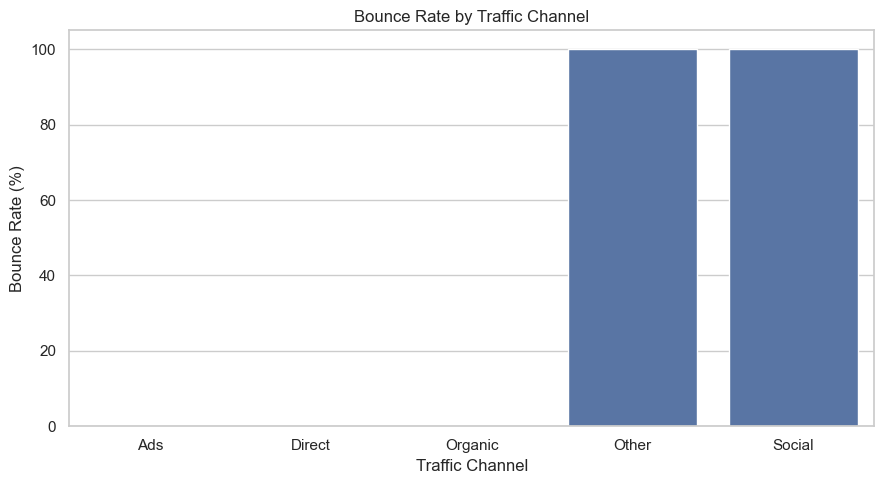

In [19]:

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=channel_summary,
    x="TrafficChannel",
    y="BounceRate",
    ax=ax
)

ax.set_title("Bounce Rate by Traffic Channel")
ax.set_xlabel("Traffic Channel")
ax.set_ylabel("Bounce Rate (%)")

plt.tight_layout()
fig.savefig(CHART_DIR / "bounce_rate_by_channel.png", dpi=200)
plt.show()


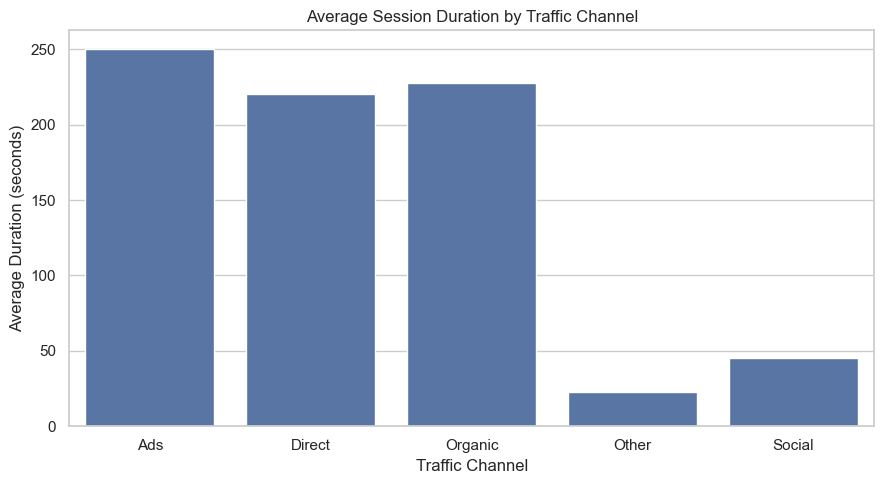

In [20]:

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=channel_summary,
    x="TrafficChannel",
    y="AvgSessionDurationSec",
    ax=ax
)

ax.set_title("Average Session Duration by Traffic Channel")
ax.set_xlabel("Traffic Channel")
ax.set_ylabel("Average Duration (seconds)")

plt.tight_layout()
fig.savefig(CHART_DIR / "session_duration_by_channel.png", dpi=200)
plt.show()


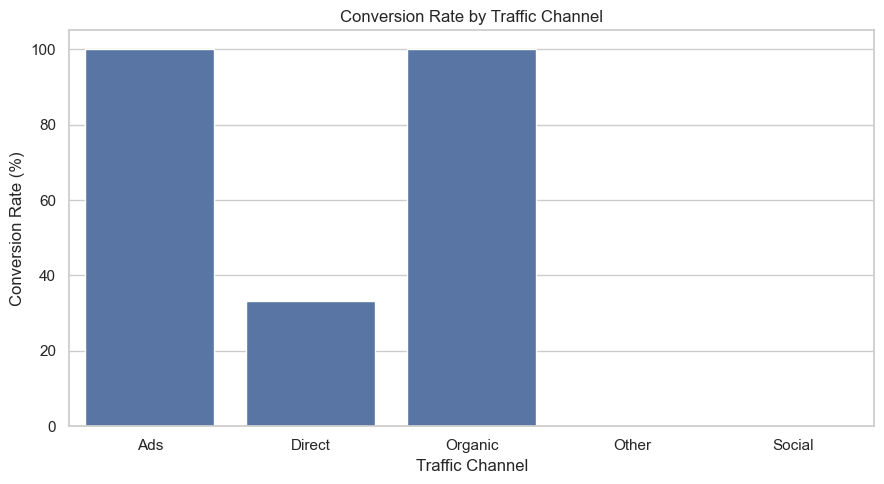

In [21]:

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=channel_summary,
    x="TrafficChannel",
    y="ConversionRate",
    ax=ax
)

ax.set_title("Conversion Rate by Traffic Channel")
ax.set_xlabel("Traffic Channel")
ax.set_ylabel("Conversion Rate (%)")

plt.tight_layout()
fig.savefig(CHART_DIR / "conversion_rate_by_channel.png", dpi=200)
plt.show()


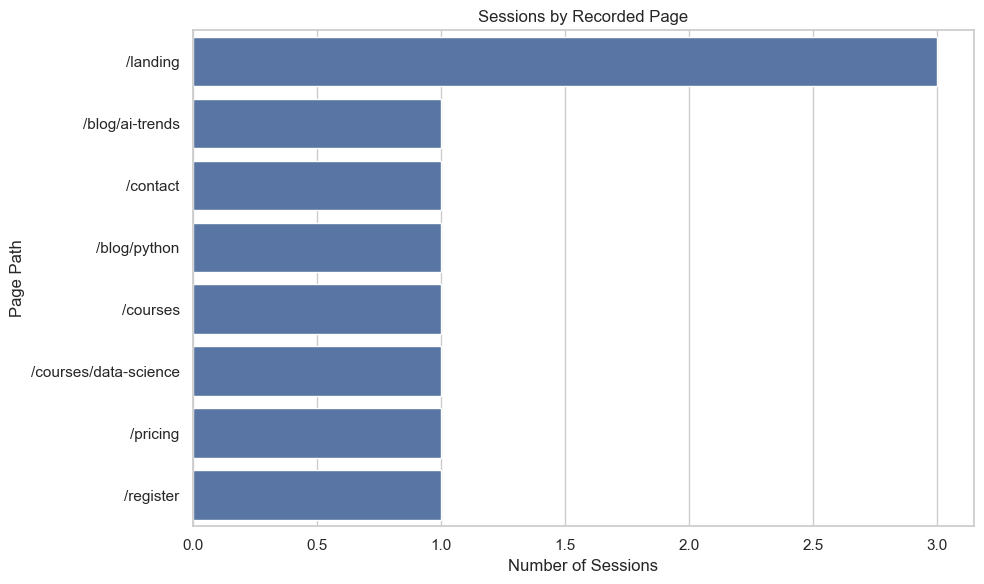

A true sequential funnel requires ordered page-event data or explicit funnel-stage fields.


In [22]:

page_plot = page_summary.sort_values("Sessions", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=page_plot,
    y="PagePath",
    x="Sessions",
    ax=ax
)

ax.set_title("Sessions by Recorded Page")
ax.set_xlabel("Number of Sessions")
ax.set_ylabel("Page Path")

plt.tight_layout()
fig.savefig(CHART_DIR / "sessions_by_page.png", dpi=200)
plt.show()

print(
    "A true sequential funnel requires ordered page-event data "
    "or explicit funnel-stage fields."
)


### Generate the PDF dashboard

In [23]:

from matplotlib.backends.backend_pdf import PdfPages

pdf_path = OUTPUT_DIR / "web_traffic_dashboard.pdf"

with PdfPages(pdf_path) as pdf:
    # Page 1: KPI summary
    fig, ax = plt.subplots(figsize=(11.7, 8.3))
    ax.axis("off")

    ax.text(
        0.5, 0.92, "WEB TRAFFIC ANALYTICS",
        ha="center", fontsize=22, fontweight="bold"
    )
    ax.text(
        0.5, 0.86, "Workora Virtual Internship",
        ha="center", fontsize=13
    )

    kpi_text = (
        f"Total Sessions: {total_sessions}\n"
        f"Total Conversions: {total_conversions}\n"
        f"Conversion Rate: {df['ConversionFlag'].mean() * 100:.2f}%\n"
        f"Bounce Rate: {df['Bounced'].mean() * 100:.2f}%\n"
        f"Average Session Duration: "
        f"{df['SessionDurationSec'].mean():.2f} seconds\n"
        f"Average Pageviews per Session: {df['PageViews'].mean():.2f}"
    )

    ax.text(
        0.12, 0.70, kpi_text,
        va="top", fontsize=15, linespacing=1.8
    )

    ax.text(
        0.12, 0.20,
        "Note: Results are based on a 10-session sample. "
        "Interpret findings cautiously.",
        fontsize=10, wrap=True
    )

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # Add chart pages
    chart_files = [
        CHART_DIR / "traffic_by_channel.png",
        CHART_DIR / "bounce_rate_by_channel.png",
        CHART_DIR / "session_duration_by_channel.png",
        CHART_DIR / "conversion_rate_by_channel.png",
        CHART_DIR / "sessions_by_page.png"
    ]

    for chart_file in chart_files:
        if chart_file.exists():
            image = plt.imread(chart_file)
            fig, ax = plt.subplots(figsize=(11.7, 8.3))
            ax.imshow(image)
            ax.axis("off")
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)

print("PDF dashboard created:", pdf_path.resolve())


PDF dashboard created: C:\Users\singh\OneDrive\Desktop\Workora Internship Tasks\Web Traffic Analytics\notebooks\outputs\web_traffic_dashboard.pdf
